# 01 · Selección del artículo y características de los datos (Etapas 1–4)

**Artículo:** Tapia, Chavez-Garzon, Pezoa, Suarez-Aldunate y Pilleux (2025). *Comparing automated valuation models for real estate assessment in the Santiago Metropolitan Region: A study on machine learning algorithms and hedonic pricing with spatial adjustments.* PLOS ONE 20(3): e0318701. https://doi.org/10.1371/journal.pone.0318701

**Datos:** los autores publicaron los datos (Mendeley Data, https://doi.org/10.17632/jdf7rzmnvw.1). El enunciado del taller permite simular los datos sólo cuando no se tienen; aquí **sí se tienen**, así que se usan los datos reales y no se simula (Etapa 4).

## Etapa 1 · Relación con el trabajo de grado
El trabajo de grado desarrolla un modelo de IA para el **avalúo predictivo de apartamentos en Bogotá y Medellín**. El artículo es un antecedente directo: es un modelo de valoración automática (AVM) de inmuebles en venta que compara un modelo de aprendizaje automático (LightGBM, interpretado con SHAP) contra un modelo hedónico con ajuste espacial (SAR), con validación cruzada. Es un artículo de revista científica (PLOS ONE), con datos tabulares y una variable objetivo continua (regresión).

Elementos que se reutilizan en el trabajo de grado: (i) el diseño comparativo ML vs. econométrico espacial, (ii) el uso de variables de ubicación y de distancia a servicios, (iii) las métricas de error (MAPE, MdAPE, MAE, RMSE, R²) y (iv) la interpretabilidad con SHAP. Lo que el artículo **no** hace y el trabajo de grado sí necesita: validación cruzada *espacial* y métricas de razón (mediana de la razón, COD y PRD) frente al margen del 7,5 % de la Resolución IGAC 620 de 2008; por eso se calculan aquí también, como complemento.

## Etapa 2 · Comprensión del estudio de los autores
| Pregunta | Respuesta (según el artículo) |
|---|---|
| Objetivo | Comparar **precisión e interpretabilidad** de dos modelos de valoración automática para la Región Metropolitana de Santiago: LightGBM (con SHAP) vs. precios hedónicos con ajuste espacial (SAR). Medir cuánto aportan las variables de imágenes. |
| Metodología | Anuncios de venta de tres portales (agosto 2020). Construcción de variables estructurales, de vecindario, de ubicación y de fotos (clasificador CNN DenseNet201, 92 % de exactitud). Modelos anidados evaluados con **validación cruzada de 5 particiones**; SHAP sobre un modelo con partición 80/20; comparación con OLS (errores robustos) y SAR (matriz de pesos KNN con k = 700). |
| Variables | Objetivo: ln(precio en UF). 45 predictoras posibles; 34 en el modelo final (Tabla 4). |
| Algoritmos | LightGBM con *boosting* DART; SHAP (TreeSHAP); OLS; SAR (modelo de rezago espacial). |
| Métricas | MAPE, MdAPE, MAE, RMSE y R² (Tabla 2), calculadas en UF. I de Moran para autocorrelación espacial. |
| Resultados principales | Con LightGBM el MAPE bajó de 11,59 % a 10,07 % al agregar variables (las fotos reducen MAE 1,2 % y MAPE 1,7 %). OLS y SAR tienen MAPE ≈ 21 %. Las variables más importantes: superficie, calidad de la comuna (ICVU), puntaje SIMCE y baños. El resultado de SHAP coincide más con OLS que con SAR (p. ej., efecto de la cercanía de colegios), lo que sugiere cautela al usar ML para inferencia. |

## Etapa 3 · Características de los datos (reales)
Cada cifra de la columna «datos reales» se calcula aquí a partir del archivo publicado por los autores.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
from src.datos_reales import cargar_reales
from src import figuras as F
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

real = cargar_reales()
fmt = lambda x: f"{x:,.0f}".replace(",", ".")
caract = pd.DataFrame([
    ("Nº de registros", "52.039 (98.630 antes de depurar)", fmt(len(real))),
    ("Valores faltantes", "—", fmt(real.isna().sum().sum())),
    ("Fecha y fuente", "agosto de 2020, tres portales (Coderhub SpA)", "Mendeley Data, doi:10.17632/jdf7rzmnvw.1"),
    ("Precio (UF)", "1.000 – 27.400", f"{fmt(real.price_uf.min())} – {fmt(real.price_uf.max())}"),
    ("Media de ln(1+precio)", "8,8 (valor base SHAP, ≈ 6.633 UF)", f"{real.ln_price.mean():.3f}"),
    ("Baños / dormitorios", "1–5 / 1–6", f"{real.bathrooms.min()}–{real.bathrooms.max()} / {real.bedrooms.min()}–{real.bedrooms.max()}"),
    ("Superficie departamentos (m²)", "15 – 400", f"{real[real.building_type==0].total_surface.min()} – {real[real.building_type==0].total_surface.max()}"),
    ("Superficie casas (m²)", "30 – 2.500", f"{real[real.building_type==1].total_surface.min()} – {fmt(real[real.building_type==1].total_surface.max())}"),
    ("Proporción de casas", "no reportada", f"{real.building_type.mean():.1%}"),
    ("Comunas con anuncios", "52 (ICVU en 42, 10 imputadas)", f"{real.municipality.nunique()}"),
    ("ICVU", "≈ 37 – 75", f"{real.quality_municipality.min():.1f} – {real.quality_municipality.max():.1f}"),
    ("SIMCE 4º básico, media", "≈ 280", f"{real.simce_4b.mean():.1f}"),
    ("Colegios a 3 km", "0 – ≈ 125", f"{real.nearby_schools_3km.min()} – {real.nearby_schools_3km.max()}"),
    ("Predictoras", "45 (7 base, 5 estructurales, 11 ubicación, 6 vecindario, 16 fotos); 34 en el modelo final",
     f"{sum(c not in ('price', 'price_uf', 'ln_price', 'municipality', 'set') for c in real.columns)} (34 en el modelo final: {len(C.VARS_FINAL)})"),
    ("Partición del autor (columna `set`)", "80 % / 20 %", " / ".join(f"{v:,}".replace(",", ".") for v in real.set.value_counts()[["Training", "Test"]])),
    ("Balance de clases", "No aplica (regresión)", "No aplica; oferta concentrada en Las Condes, Santiago y Vitacura"),
], columns=["Característica", "Reportado por el artículo", "Datos reales"])
caract

d:\academico\maestria_analitica_aplicada\semestre 2\Machine Learning 2\proyecto\proyecto_ajustes\proyecto_ml_final_datos_reales\proyecto_ml_final\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Característica,Reportado por el artículo,Datos reales
0,Nº de registros,52.039 (98.630 antes de depurar),52.039
1,Valores faltantes,—,0
2,Fecha y fuente,"agosto de 2020, tres portales (Coderhub SpA)","Mendeley Data, doi:10.17632/jdf7rzmnvw.1"
3,Precio (UF),1.000 – 27.400,1.000 – 27.400
4,Media de ln(1+precio),"8,8 (valor base SHAP, ≈ 6.633 UF)",8.783
5,Baños / dormitorios,1–5 / 1–6,1–5 / 1–6
6,Superficie departamentos (m²),15 – 400,15 – 400
7,Superficie casas (m²),30 – 2.500,30 – 2.400
8,Proporción de casas,no reportada,38.4%
9,Comunas con anuncios,"52 (ICVU en 42, 10 imputadas)",49


In [2]:
print("Anuncios por comuna (las 8 con más):"); print(real.municipality.value_counts().head(8).to_string())
real[["price_uf", "ln_price", "total_surface", "bathrooms", "bedrooms", "quality_municipality", "simce_4b",
      "nearby_schools_3km", "dist_subway", "dist_university"]].describe().round(2).T

Anuncios por comuna (las 8 con más):
municipality
Las Condes      9406
Santiago        5454
Vitacura        4565
Lo Barnechea    4270
Providencia     4056
Ñuñoa           3918
La Florida      2019
Colina          1752


,count,mean,std,min,25%,50%,75%,max
price_uf,52039.0,8594.87,6245.55,1000.00,3364.41,6700.00,12300.00,27400.00
ln_price,52039.0,8.78,0.77,6.91,8.12,8.81,9.42,10.22
total_surface,52039.0,203.08,231.42,15.00,67.00,125.00,235.00,2400.00
bathrooms,52039.0,2.36,1.06,1.00,2.00,2.00,3.00,5.00
bedrooms,52039.0,3.03,1.17,1.00,2.00,3.00,4.00,6.00
quality_municipality,52039.0,63.62,9.36,38.08,55.87,66.28,74.54,75.59
simce_4b,52039.0,278.92,16.02,202.00,266.08,280.40,290.60,319.50
nearby_schools_3km,52039.0,59.79,35.45,0.00,29.00,55.00,93.00,129.00
dist_subway,52039.0,2.72,4.11,0.00,0.46,1.05,3.20,48.23
dist_university,52039.0,2.52,3.74,0.00,0.57,1.22,2.77,51.36


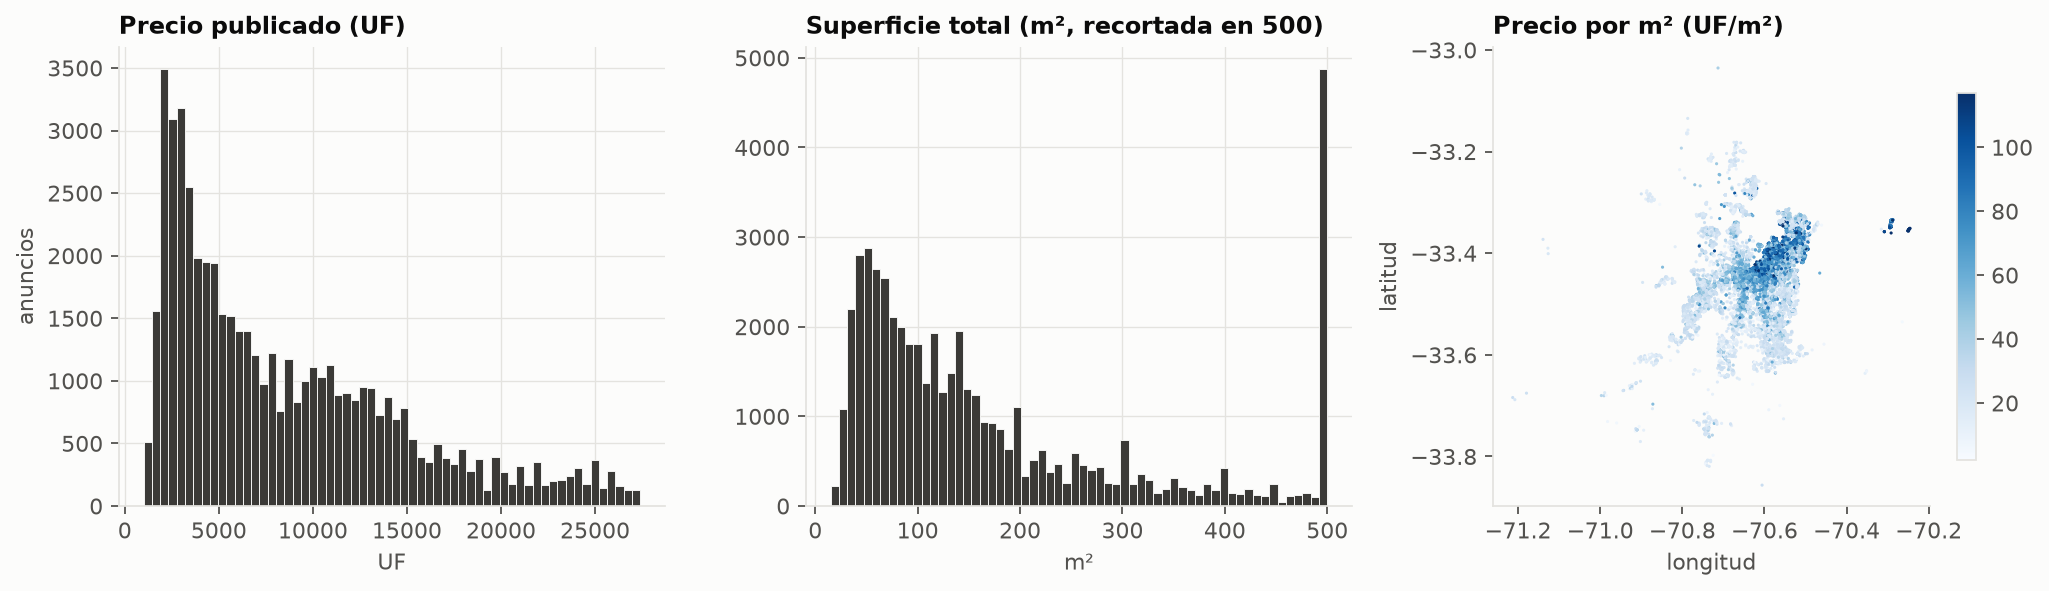

In [3]:
display(Image(str(F.fig_distribuciones(real, "real"))))

## Etapa 4 · Simulación del conjunto de datos: no aplica
El enunciado del taller indica simular los datos sólo cuando el artículo no los publica. Los autores publicaron los suyos (Mendeley Data), así que se usan directamente y no se simula ningún conjunto.

In [4]:
# Variables de ubicación y vecindario: ¿cómo se relacionan con el precio? (Spearman con ln(1+precio))
grupos = {"vivienda": ["total_surface", "bathrooms", "bedrooms", "building_type", "parking_lots"],
          "comuna y entorno": ["quality_municipality", "simce_4b", "nearby_schools_3km", "dist_subway", "dist_university"]}
pd.Series({v: real[v].corr(real["ln_price"], method="spearman") for g in grupos.values() for v in g}, name="correlación de Spearman con ln_price").round(3).to_frame()

,correlación de Spearman con ln_price
total_surface,0.767
bathrooms,0.775
bedrooms,0.580
building_type,0.188
parking_lots,0.310
quality_municipality,0.656
simce_4b,0.725
nearby_schools_3km,-0.601
dist_subway,0.358
dist_university,0.076
